# Architecture zoo: does leakage change explanations for *every* model type, and does an XAI-guided model fix inter-patient S detection?

The same rebuilt MIT-BIH beats and the same two splits (**intra** = leaky random, **inter** = DS1 → DS2 patients) are used for 8 architectures:

| Model | Family | Source |
|---|---|---|
| `ResNet` | Residual CNN | Kachuee et al. 2018 (reference) |
| `CNN` | Plain 1-D CNN | baseline |
| `GRU` | RNN | baseline |
| `BiLSTM` | RNN (bidirectional) | baseline |
| `CNN_BiLSTM` | CNN + RNN hybrid | common in the ECG literature |
| `Transformer` | CNN stem + multi-head self-attention | in the spirit of DeepECG-Net (Alghieth 2025); exact sizes are not given in that paper |
| `ECGNet_AELU` | Dense 256→128 with AELU | core of ECGNet (Abubakar 2025), which was designed for ECG *images*; here applied to raw beats |
| `RR_ResNet` (**proposed**) | ResNet waveform branch + RR-timing branch | motivated by paper-2 XAI: leaky models detect S from end-of-window timing, a cue that does not transfer. Here timing is given *explicitly* as patient-normalised RR features |

**Honesty note on `RR_ResNet`:** RR-interval features are long established (de Chazal 2004 and later work). What is new is that the design is motivated, and then checked, by the explanation analysis. It is not a new feature type.

## Hypotheses
| # | Hypothesis | Metric | Negative result |
|---|---|---|---|
| Z1 | The intra→inter collapse holds for every architecture | 4-class (N,S,V,F) macro-F1 intra vs inter, per model | some model shows no gap |
| Z2 | The explanation shift under leakage is architecture-general | Δ = within-arm − cross-arm attribution agreement > 0 (CI), per model and method, on **all** pool beats of N/S/V/F (attributed to the true class, not only correctly classified ones) | Δ ≈ 0 for most models |
| Z3 | The QRS-width → V rule survives leakage in every model | ΔP(V) for N beats with QRS×2: > 0 in both arms | effect absent, or present only in intra |
| Z4 | Explicit, patient-normalised RR timing improves inter-patient S detection | inter S recall and 4-class F1: RR_ResNet vs ResNet (seed mean ± std) | no gain beyond seed std |

**Practical:** each trained model is saved. If Colab disconnects, Run all resumes and skips finished models. Outputs go next to your data folder on Drive (so they survive the session) when the data is on Drive.

In [1]:
import os, json, time, math, random, warnings, itertools, contextlib
from pathlib import Path
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib
if os.environ.get("MPLBACKEND") == "Agg": matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy import signal as sps
from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, recall_score
warnings.filterwarnings("ignore")
try:
    import wfdb
except ImportError:
    import subprocess, sys; subprocess.run([sys.executable, "-m", "pip", "install", "-q", "wfdb"], check=True); import wfdb

FAST_MODE     = os.environ.get("ECG_FAST", "0") == "1"
USE_SYNTHETIC = os.environ.get("ECG_SYNTHETIC", "0") == "1"
DATA_DIR_HINTS = [os.environ.get("MITDB_DIR", ""), "/content/MyDrive/Research/cardio", "/content/drive/MyDrive/Research/cardio",
                  "/kaggle/input/mitbih-arrhythmia-database", "./mitdb"]
ARCHS = ["ResNet", "CNN", "GRU", "BiLSTM", "CNN_BiLSTM", "Transformer", "ECGNet_AELU", "RR_ResNet"]   # trim this list to save time
SEEDS       = [0, 1] if FAST_MODE else [0, 1, 2]
EPOCHS      = 2 if FAST_MODE else 30
PATIENCE    = 1 if FAST_MODE else 6
BATCH       = 256
N_PER_CLASS = 5 if FAST_MODE else 100
IG_STEPS    = 6 if FAST_MODE else 32
SG_N, SG_SIGMA = (3 if FAST_MODE else 16), 0.10
OCC_W, OCC_S = 9, 3
N_BOOT      = 200 if FAST_MODE else 2000
METHODS     = ["SmoothGrad", "IntGrad", "Occlusion", "Random"]; SIGNED = {"IntGrad", "Occlusion"}

FS_RAW, FS, SIG_LEN, WIN = 360, 125, 187, 1250
CLASSES = ["N", "S", "V", "F", "Q"]; C4 = [0, 1, 2, 3]; ARMS = ["intra", "inter"]
AAMI = {**{s: 0 for s in "NLRej"}, **{s: 1 for s in "AaJS"}, **{s: 2 for s in "VE"}, "F": 3, **{s: 4 for s in "/fQ"}}
DS1 = [101, 106, 108, 109, 112, 114, 115, 116, 118, 119, 122, 124, 201, 203, 205, 207, 208, 209, 215, 220, 223, 230]
DS2 = [100, 103, 105, 111, 113, 117, 121, 123, 200, 202, 210, 212, 213, 214, 219, 221, 222, 228, 231, 232, 233, 234]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams.update({"font.size": 11, "axes.titlesize": 12, "legend.fontsize": 9, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})
ACOL = {"intra": "#c44e52", "inter": "#4c72b0"}

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
def boot_ci(v, n=N_BOOT, seed=0):
    v = np.asarray(v, float); v = v[~np.isnan(v)]
    if len(v) < 2: return (np.nan, np.nan)
    b = v[np.random.default_rng(seed).integers(0, len(v), (n, len(v)))].mean(1); return (float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5)))
print(f"FAST={FAST_MODE} SYNTHETIC={USE_SYNTHETIC} device={DEVICE} archs={ARCHS}")

FAST=False SYNTHETIC=False device=cuda archs=['ResNet', 'CNN', 'GRU', 'BiLSTM', 'CNN_BiLSTM', 'Transformer', 'ECGNet_AELU', 'RR_ResNet']


## Data: the same Kachuee-recipe beats as paper 2, plus RR-timing features per beat
RR features, computed from the annotated R-peaks of each record: pre-RR, post-RR, local mean RR (the previous 10 beats), and pre/local and post/local ratios. The ratios normalise each patient's own heart rate away, which is what should transfer to new patients. Note that post-RR uses the next beat, which is standard for offline beat classification (de Chazal 2004).

In [2]:
def write_synthetic_mitdb(d, seconds):
    """Synthetic WFDB records (for testing the pipeline only). Patient-specific morphology makes inter-patient harder."""
    d.mkdir(parents=True, exist_ok=True); rng = np.random.default_rng(7)
    sym_for = {0: "N", 1: "A", 2: "V", 3: "F", 4: "Q"}
    for rid in DS1 + DS2:
        hr = rng.uniform(55, 105); wscale = rng.uniform(.8, 1.3); tscale = rng.uniform(.6, 1.4)
        mix = rng.dirichlet(np.array([.75, .07, .1, .03, .05]) * 10 + .05)
        n = seconds * FS_RAW; t = np.arange(n); x = np.zeros(n); samples, symbols = [], []
        pos = int(.5 * FS_RAW)
        while pos < n - FS_RAW:
            c = rng.choice(5, p=mix); rr = 60 / hr * FS_RAW * rng.uniform(.95, 1.05)
            if c in (1, 2): pos = int(pos - .25 * rr)   # premature
            w = {0: 7, 1: 7, 2: 18, 3: 12, 4: 9}[c] * wscale; ta = {0: .3, 1: .28, 2: -.35, 3: .1, 4: .25}[c] * tscale
            seg = slice(max(pos - 150, 0), min(pos + 300, n)); tt = t[seg] - pos
            x[seg] += np.exp(-.5 * (tt / w) ** 2) - .2 * np.exp(-.5 * ((tt - 2.5 * w) / w) ** 2) + ta * np.exp(-.5 * ((tt - .3 * rr) / (.06 * rr)) ** 2)
            if c != 1: x[seg] += .1 * np.exp(-.5 * ((tt + .2 * FS_RAW) / 10) ** 2)
            if c == 4: x[pos:pos + 3] += .5
            samples.append(pos); symbols.append(sym_for[c]); pos = int(pos + rr * (1.3 if c == 2 else 1.0))
        x += .03 * rng.standard_normal(n) + .1 * np.sin(2 * np.pi * t / (3 * FS_RAW))
        sig = np.stack([x, .5 * x + .02 * rng.standard_normal(n)], 1)
        wfdb.wrsamp(str(rid), fs=FS_RAW, units=["mV", "mV"], sig_name=["MLII", "V5"], p_signal=sig, fmt=["212", "212"], write_dir=str(d))
        wfdb.wrann(str(rid), "atr", np.array(samples), symbol=symbols, write_dir=str(d))
    return d

def find_mitdb():
    if USE_SYNTHETIC: return write_synthetic_mitdb(Path("synthetic_mitdb"), 120 if FAST_MODE else 600)
    for h in DATA_DIR_HINTS:
        if h and Path(h).exists():
            hit = next(Path(h).rglob("100.hea"), None)
            if hit: return hit.parent
    if Path("/content").exists() and not Path("/content/drive").exists():
        try:
            from google.colab import drive; drive.mount("/content/drive")
            for h in DATA_DIR_HINTS:
                hit = next(Path(h).rglob("100.hea"), None) if h and Path(h).exists() else None
                if hit: return hit.parent
        except Exception as e: print("Drive mount skipped:", e)
    print("Downloading MIT-BIH from PhysioNet (~100 MB) ..."); wfdb.dl_database("mitdb", dl_dir="mitdb"); return Path("mitdb")
def build_record(d, rid):
    rec = wfdb.rdrecord(str(d / str(rid))); ann = wfdb.rdann(str(d / str(rid)), "atr")
    ch = rec.sig_name.index("MLII") if "MLII" in rec.sig_name else 0
    x = sps.resample_poly(rec.p_signal[:, ch], 25, 72)
    sym = np.array(ann.symbol); ok = np.isin(sym, list(AAMI))
    r = np.round(ann.sample[ok] * FS / FS_RAW).astype(int); lab = np.array([AAMI[s] for s in sym[ok]])
    for i in range(len(r)):
        lo, hi = max(r[i] - 3, 0), min(r[i] + 4, len(x)); r[i] = lo + int(np.argmax(x[lo:hi]))
    X, Y, W, R = [], [], [], []
    for w0 in range(0, len(x) - WIN + 1, WIN):
        idx = np.where((r >= w0) & (r < w0 + WIN))[0]
        if len(idx) < 2: continue
        Lc = int(min(round(1.2 * np.median(np.diff(r[idx]))), SIG_LEN)); seg = x[w0:w0 + WIN]; lo, hi = seg.min(), seg.max()
        for i in idx:
            if i == 0 or i == len(r) - 1: continue
            crop = x[r[i]:r[i] + Lc]
            if len(crop) < Lc: continue
            pre, post = (r[i] - r[i - 1]) / FS, (r[i + 1] - r[i]) / FS; loc = np.mean(np.diff(r[max(0, i - 10):i + 1])) / FS
            b = np.zeros(SIG_LEN, np.float32); b[:Lc] = np.clip((crop - lo) / (hi - lo + 1e-8), 1e-4, 1)
            X.append(b); Y.append(lab[i]); W.append(w0 // WIN); R.append([pre, post, loc, pre / loc, post / loc])
    return np.array(X), np.array(Y), np.array(W), np.array(R, np.float32)

t0 = time.time(); MITDB = find_mitdb(); print("Records from:", MITDB)
OUT = Path(os.environ.get("OUT_DIR", "")) if os.environ.get("OUT_DIR") else (MITDB.parent / "outputs_zoo" if "drive" in str(MITDB).lower() or "MyDrive" in str(MITDB) else Path("outputs_zoo"))
FIG, MOD = OUT / "figures", OUT / "models"; FIG.mkdir(parents=True, exist_ok=True); MOD.mkdir(parents=True, exist_ok=True); print("Outputs ->", OUT.resolve())
parts = [(rid,) + build_record(MITDB, rid) for rid in DS1 + DS2]
X_all = np.concatenate([p[1] for p in parts]); y_all = np.concatenate([p[2] for p in parts]); RR_all = np.concatenate([p[4] for p in parts])
rec_all = np.concatenate([np.full(len(p[2]), p[0]) for p in parts]); is_ds1 = np.isin(rec_all, DS1)
print(pd.DataFrame({"DS1": np.bincount(y_all[is_ds1], minlength=5), "DS2": np.bincount(y_all[~is_ds1], minlength=5)}, index=CLASSES), f"\n{len(y_all)} beats, {time.time() - t0:.0f}s")
idx_all = np.arange(len(y_all))
tr_i, te_i = train_test_split(idx_all, test_size=.2, stratify=y_all, random_state=0); tr_i, va_i = train_test_split(tr_i, test_size=.1, stratify=y_all[tr_i], random_state=0)
ds1, ds2 = idx_all[is_ds1], idx_all[~is_ds1]; strat = lambda ix: y_all[ix] if np.bincount(y_all[ix]).min() >= 2 else None
tr_x, va_x = train_test_split(ds1, test_size=.1, stratify=strat(ds1), random_state=0)
SPLIT = {"intra": dict(tr=tr_i, va=va_i, te=te_i), "inter": dict(tr=tr_x, va=va_x, te=ds2)}
POOL = np.intersect1d(te_i, ds2); print("evaluation pool per class:", np.bincount(y_all[POOL], minlength=5))
RR_STATS = {a: (RR_all[SPLIT[a]["tr"]].mean(0), RR_all[SPLIT[a]["tr"]].std(0) + 1e-6) for a in ARMS}   # standardise with train stats only
RESULTS = {"config": dict(FAST_MODE=FAST_MODE, SYNTHETIC=USE_SYNTHETIC, ARCHS=ARCHS, SEEDS=SEEDS, EPOCHS=EPOCHS, N_PER_CLASS=N_PER_CLASS, device=str(DEVICE)),
           "n_beats": int(len(y_all)), "pool_per_class": np.bincount(y_all[POOL], minlength=5).tolist()}
def save_results():
    conv = lambda o: o.item() if isinstance(o, (np.floating, np.integer)) else (o.tolist() if isinstance(o, np.ndarray) else str(o))
    (OUT / "results.json").write_text(json.dumps(RESULTS, indent=2, default=conv))
def savefig(fig, name): fig.savefig(FIG / f"{name}.png"); plt.show(); plt.close(fig)
def valid_len(X):
    X = np.atleast_2d(X); nz = X != 0; return np.where(nz.any(1), SIG_LEN - np.argmax(nz[:, ::-1], 1), 0)

Mounted at /content/drive
Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Generating record list for: 208
Generating rec

## The 8 architectures
Every model has the signature `model(x, rr)`. Only `RR_ResNet` uses `rr`; the others ignore it. All explanations are computed with respect to the waveform `x`, with `rr` held fixed.

In [3]:
class ResBlock(nn.Module):
    def __init__(s, c=32):
        super().__init__(); s.c1 = nn.Conv1d(c, c, 5, padding=2); s.c2 = nn.Conv1d(c, c, 5, padding=2); s.pool = nn.MaxPool1d(5, 2)
    def forward(s, x): return s.pool(F.relu(s.c2(F.relu(s.c1(x))) + x))
class ResNet(nn.Module):                                   # Kachuee 2018
    is_rnn = False
    def __init__(s, n=5, use_rr=False):
        super().__init__(); s.use_rr = use_rr; s.conv0 = nn.Conv1d(1, 32, 5, padding=2); s.blocks = nn.Sequential(*[ResBlock() for _ in range(5)])
        s.rr = nn.Sequential(nn.Linear(5, 16), nn.ReLU()) if use_rr else None
        s.fc1 = nn.Linear(64 + (16 if use_rr else 0), 32); s.fc2 = nn.Linear(32, 32); s.out = nn.Linear(32, n)
    def forward(s, x, rr=None):
        h = s.blocks(s.conv0(x[:, None])).flatten(1)
        if s.use_rr: h = torch.cat([h, s.rr(rr)], 1)
        return s.out(F.relu(s.fc2(F.relu(s.fc1(h)))))
class CNN(nn.Module):
    is_rnn = False
    def __init__(s, n=5):
        super().__init__(); L = []
        for ci, co in [(1, 32), (32, 64), (64, 128)]: L += [nn.Conv1d(ci, co, 7, padding=3), nn.BatchNorm1d(co), nn.ReLU(), nn.MaxPool1d(2)]
        s.f = nn.Sequential(*L); s.out = nn.Sequential(nn.Dropout(.2), nn.Linear(128, n))
    def forward(s, x, rr=None): return s.out(s.f(x[:, None]).mean(2))
class GRU(nn.Module):
    is_rnn = True
    def __init__(s, n=5):
        super().__init__(); s.rnn = nn.GRU(1, 64, num_layers=2, batch_first=True, dropout=.2); s.out = nn.Linear(64, n)
    def forward(s, x, rr=None): o, _ = s.rnn(x[:, :, None]); return s.out(o[:, -1])
class BiLSTM(nn.Module):
    is_rnn = True
    def __init__(s, n=5):
        super().__init__(); s.rnn = nn.LSTM(1, 64, num_layers=2, batch_first=True, bidirectional=True, dropout=.2); s.out = nn.Linear(256, n)
    def forward(s, x, rr=None): o, _ = s.rnn(x[:, :, None]); return s.out(torch.cat([o.mean(1), o.amax(1)], 1))
class CNN_BiLSTM(nn.Module):
    is_rnn = True
    def __init__(s, n=5):
        super().__init__()
        s.f = nn.Sequential(nn.Conv1d(1, 32, 5, padding=2), nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
                            nn.Conv1d(32, 64, 5, padding=2), nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2))
        s.rnn = nn.LSTM(64, 64, batch_first=True, bidirectional=True); s.out = nn.Linear(256, n)
    def forward(s, x, rr=None): o, _ = s.rnn(s.f(x[:, None]).transpose(1, 2)); return s.out(torch.cat([o.mean(1), o.amax(1)], 1))
class Transformer(nn.Module):                              # DeepECG-Net-style CNN + MHSA
    is_rnn = False
    def __init__(s, n=5, d=64):
        super().__init__(); s.stem = nn.Sequential(nn.Conv1d(1, d, 7, stride=2, padding=3), nn.BatchNorm1d(d), nn.ReLU())
        s.pos = nn.Parameter(torch.zeros(1, 94, d)); nn.init.normal_(s.pos, std=.02)
        s.enc = nn.TransformerEncoder(nn.TransformerEncoderLayer(d, 4, 128, dropout=.1, batch_first=True), num_layers=2); s.out = nn.Linear(d, n)
    def forward(s, x, rr=None): return s.out(s.enc(s.stem(x[:, None]).transpose(1, 2) + s.pos).mean(1))
class AELU(nn.Module):                                     # Abubakar 2025, Eq. 2: x+b (x>0); a(exp(x)-1)+b (x<=0)
    def __init__(s, a=1.0, b=0.1): super().__init__(); s.a, s.b = a, b
    def forward(s, x): return torch.where(x > 0, x + s.b, s.a * (torch.exp(torch.clamp(x, max=0)) - 1) + s.b)
class ECGNet_AELU(nn.Module):                              # ECGNet core: dense 256 -> 128 with BN, dropout, AELU
    is_rnn = False
    def __init__(s, n=5):
        super().__init__(); s.f = nn.Sequential(nn.Linear(SIG_LEN, 256), nn.BatchNorm1d(256), AELU(), nn.Dropout(.3),
                                                nn.Linear(256, 128), nn.BatchNorm1d(128), AELU(), nn.Dropout(.3), nn.Linear(128, n))
    def forward(s, x, rr=None): return s.f(x)
def make(arch):
    return {"ResNet": lambda: ResNet(), "CNN": CNN, "GRU": GRU, "BiLSTM": BiLSTM, "CNN_BiLSTM": CNN_BiLSTM, "Transformer": Transformer,
            "ECGNet_AELU": ECGNet_AELU, "RR_ResNet": lambda: ResNet(use_rr=True)}[arch]().to(DEVICE)
for a_ in ARCHS: print(f"{a_:12s} params={sum(p.numel() for p in make(a_).parameters()):,}")

ResNet       params=55,013
CNN          params=73,221
GRU          params=38,149
BiLSTM       params=134,917
CNN_BiLSTM   params=78,533
Transformer  params=73,925
ECGNet_AELU  params=82,437
RR_ResNet    params=55,621


## Train (or resume) every architecture × arm × seed
The data is placed on the GPU once, so training isn't bottlenecked on copying. Model selection uses validation **4-class** macro-F1.

  ResNet       intra s0: trained 30 ep, val F1(4)=0.880   test F1(4)=0.879 (57s)
  ResNet       intra s1: trained 13 ep, val F1(4)=0.763   test F1(4)=0.741 (22s)
  ResNet       intra s2: trained 30 ep, val F1(4)=0.838   test F1(4)=0.834 (49s)
  ResNet       inter s0: trained 30 ep, val F1(4)=0.907   test F1(4)=0.387 (31s)
  ResNet       inter s1: trained 30 ep, val F1(4)=0.877   test F1(4)=0.353 (31s)
  ResNet       inter s2: trained 30 ep, val F1(4)=0.878   test F1(4)=0.382 (31s)
  CNN          intra s0: trained 8 ep, val F1(4)=0.705    test F1(4)=0.685 (8s)
  CNN          intra s1: trained 13 ep, val F1(4)=0.742   test F1(4)=0.734 (13s)
  CNN          intra s2: trained 27 ep, val F1(4)=0.741   test F1(4)=0.731 (27s)
  CNN          inter s0: trained 9 ep, val F1(4)=0.599    test F1(4)=0.460 (6s)
  CNN          inter s1: trained 15 ep, val F1(4)=0.804   test F1(4)=0.504 (9s)
  CNN          inter s2: trained 23 ep, val F1(4)=0.807   test F1(4)=0.484 (15s)
  GRU          intra s0: traine

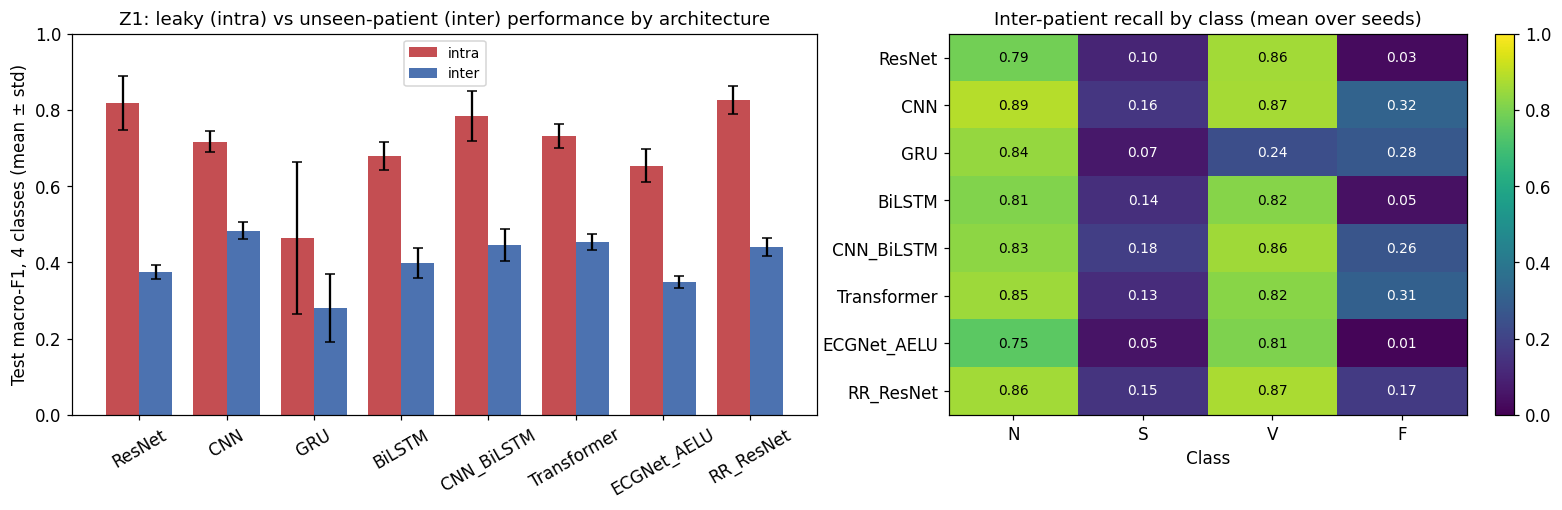

In [4]:
GX = torch.as_tensor(X_all, device=DEVICE); GY = torch.as_tensor(y_all, device=DEVICE)
GRR = {a: torch.as_tensor((RR_all - RR_STATS[a][0]) / RR_STATS[a][1], device=DEVICE) for a in ARMS}
def rnn_ctx(m): return torch.backends.cudnn.flags(enabled=False) if getattr(m, "is_rnn", False) and DEVICE.type == "cuda" else contextlib.nullcontext()
def predict_proba(m, ix, arm, bs=4096):
    m.eval(); ix = torch.as_tensor(ix, device=DEVICE)
    with torch.no_grad(): return torch.cat([F.softmax(m(GX[ix[i:i + bs]], GRR[arm][ix[i:i + bs]]), 1) for i in range(0, len(ix), bs)]).cpu().numpy()
def f1_4(y, yp): return float(f1_score(y, yp, labels=C4, average="macro", zero_division=0))
def train_model(arch, arm, seed):
    f = MOD / f"{arch}_{arm}_s{seed}.pt"; m = make(arch)
    if f.exists(): m.load_state_dict(torch.load(f, map_location=DEVICE)); m.eval(); return m, "loaded"
    set_seed(seed); m = make(arch); S = SPLIT[arm]; tr = torch.as_tensor(S["tr"], device=DEVICE)
    cnt = np.bincount(y_all[S["tr"]], minlength=5).astype(float); w = cnt.sum() / (5 * np.maximum(cnt, 1))
    lossf = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32, device=DEVICE))
    opt = torch.optim.Adam(m.parameters(), 1e-3); sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, "max", .5, 3)
    g = torch.Generator(device="cpu").manual_seed(seed); best, state, bad = -1, None, 0
    for ep in range(EPOCHS):
        m.train(); perm = tr[torch.randperm(len(tr), generator=g).to(DEVICE)]
        for i in range(0, len(perm), BATCH):
            j = perm[i:i + BATCH]; opt.zero_grad(); loss = lossf(m(GX[j], GRR[arm][j]), GY[j]); loss.backward()
            nn.utils.clip_grad_norm_(m.parameters(), 5.0); opt.step()
        v = f1_4(y_all[S["va"]], predict_proba(m, S["va"], arm).argmax(1)); sch.step(v)
        if v > best: best, state, bad = v, {k: t.detach().clone() for k, t in m.state_dict().items()}, 0
        else: bad += 1
        if bad >= PATIENCE: break
    m.load_state_dict(state); m.eval(); torch.save(state, f); return m, f"trained {ep + 1} ep, val F1(4)={best:.3f}"

MODELS, PERF_ROWS = {}, []; t0 = time.time()
for arch in ARCHS:
    for arm in ARMS:
        for s in SEEDS:
            t1 = time.time(); m, msg = train_model(arch, arm, s); MODELS[(arch, arm, s)] = m
            te = SPLIT[arm]["te"]; yp = predict_proba(m, te, arm).argmax(1); rec = recall_score(y_all[te], yp, labels=range(5), average=None, zero_division=0)
            PERF_ROWS.append(dict(arch=arch, arm=arm, seed=s, f1_4=f1_4(y_all[te], yp), f1_5=float(f1_score(y_all[te], yp, labels=range(5), average="macro", zero_division=0)),
                                  **{f"rec_{c}": float(r) for c, r in zip(CLASSES, rec)}))
            print(f"  {arch:12s} {arm:5s} s{s}: {msg:32s} test F1(4)={PERF_ROWS[-1]['f1_4']:.3f} ({time.time() - t1:.0f}s)")
PERF = pd.DataFrame(PERF_ROWS); PERF.to_csv(OUT / "performance_per_seed.csv", index=False)
PS = PERF.groupby(["arch", "arm"]).agg(["mean", "std"]).drop(columns="seed"); PS.to_csv(OUT / "performance_summary.csv")
print(PERF.groupby(["arch", "arm"])[["f1_4", "rec_N", "rec_S", "rec_V", "rec_F"]].mean().round(3).unstack("arm").to_string())
_p = PERF.groupby(["arch", "arm"])[["f1_4", "rec_N", "rec_S", "rec_V", "rec_F"]].agg(["mean", "std"]).round(4); _p.columns = [f"{a}_{b}" for a, b in _p.columns]
RESULTS["performance"] = _p.reset_index().to_dict("records")
save_results(); print(f"training block {time.time() - t0:.0f}s")

fig, axes = plt.subplots(1, 2, figsize=(17, 4.5), gridspec_kw={"width_ratios": [1.3, 1]})
xa = np.arange(len(ARCHS))
for k, arm in enumerate(ARMS):
    mu = [PERF[(PERF.arch == a_) & (PERF.arm == arm)].f1_4.mean() for a_ in ARCHS]; sd = [PERF[(PERF.arch == a_) & (PERF.arm == arm)].f1_4.std() for a_ in ARCHS]
    axes[0].bar(xa + (k - .5) * .38, mu, .38, yerr=sd, capsize=3, color=ACOL[arm], label=arm)
axes[0].set_xticks(xa, ARCHS, rotation=30); axes[0].set_ylabel("Test macro-F1, 4 classes (mean ± std)"); axes[0].set_ylim(0, 1)
axes[0].set_title("Z1: leaky (intra) vs unseen-patient (inter) performance by architecture"); axes[0].legend()
H = np.array([[PERF[(PERF.arch == a_) & (PERF.arm == "inter")][f"rec_{c}"].mean() for c in CLASSES[:4]] for a_ in ARCHS])
im = axes[1].imshow(H, cmap="viridis", vmin=0, vmax=1, aspect="auto")
for i in range(len(ARCHS)):
    for j in range(4): axes[1].text(j, i, f"{H[i, j]:.2f}", ha="center", va="center", color="white" if H[i, j] < .5 else "black", fontsize=9)
axes[1].set_xticks(range(4), CLASSES[:4]); axes[1].set_yticks(range(len(ARCHS)), ARCHS); axes[1].set_xlabel("Class")
axes[1].set_title("Inter-patient recall by class (mean over seeds)"); fig.colorbar(im, ax=axes[1], fraction=.046); savefig(fig, "01_performance_zoo")

## Z2 · Explanation shift under leakage, for every architecture
Pool beats of N, S, V and F (up to `N_PER_CLASS` each) are attributed toward the **true class**, whether or not the model predicts it, so S and F are no longer dropped. Δ = mean within-arm seed↔seed Spearman ρ of |attribution| minus cross-arm ρ. Random is the control and should give Δ ≈ 0.

explained beats per class: [100 100 100  82   0]
  ResNet: done (13s)
  CNN: done (25s)
  GRU: done (63s)
  BiLSTM: done (127s)
  CNN_BiLSTM: done (153s)
  Transformer: done (167s)
  ECGNet_AELU: done (179s)
  RR_ResNet: done (193s)
       arch     method  within  cross  shift  ci_lo  ci_hi
     BiLSTM    IntGrad   0.749  0.719  0.030  0.028  0.033
     BiLSTM  Occlusion   0.912  0.903  0.010  0.008  0.012
     BiLSTM     Random   0.002 -0.000  0.002 -0.002  0.006
     BiLSTM SmoothGrad   0.606  0.590  0.016  0.011  0.021
        CNN    IntGrad   0.610  0.604  0.007  0.004  0.009
        CNN  Occlusion   0.927  0.911  0.015  0.013  0.018
        CNN     Random   0.002 -0.000  0.002 -0.002  0.006
        CNN SmoothGrad   0.343  0.324  0.019  0.014  0.024
 CNN_BiLSTM    IntGrad   0.723  0.713  0.010  0.008  0.012
 CNN_BiLSTM  Occlusion   0.914  0.907  0.008  0.006  0.009
 CNN_BiLSTM     Random   0.002 -0.000  0.002 -0.002  0.006
 CNN_BiLSTM SmoothGrad   0.499  0.524 -0.025 -0.030 -0.021


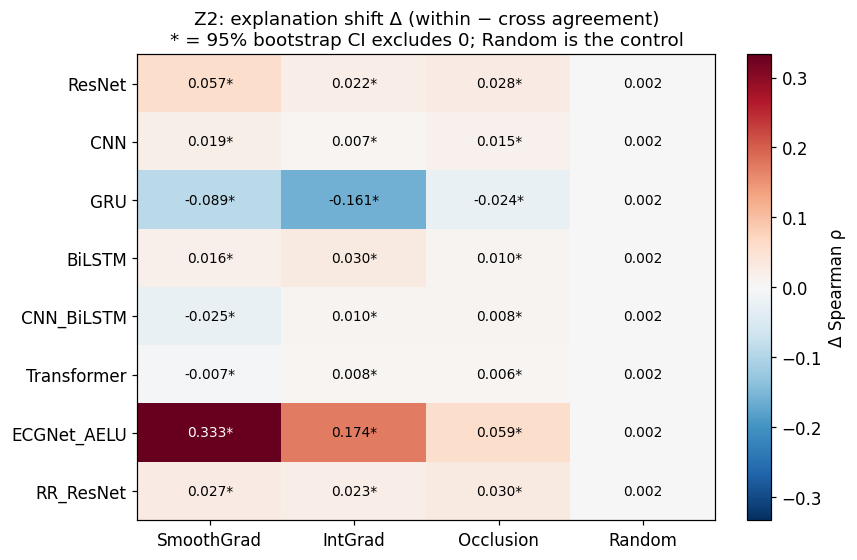

In [5]:
def _ix(ix): return torch.as_tensor(ix, device=DEVICE)
def grad_logit(m, x, rr, tgt):
    x = x.clone().requires_grad_(True)
    with rnn_ctx(m): g, = torch.autograd.grad(m(x, rr).gather(1, tgt[:, None]).sum(), x)
    return g
def prob(m, x, rr, tgt):
    with torch.no_grad(): return F.softmax(m(x, rr), 1).gather(1, tgt[:, None])[:, 0]
def attribute(m, ix, arm, method, rng, mean_beat):
    m.eval(); ix = _ix(ix); x = GX[ix]; rr = GRR[arm][ix]; tgt = GY[ix]
    if method == "Random": return rng.random(tuple(x.shape))
    if method == "SmoothGrad":
        acc = torch.zeros_like(x)
        for _ in range(SG_N): acc += grad_logit(m, x + SG_SIGMA * torch.randn_like(x), rr, tgt).abs()
        return (acc / SG_N).cpu().numpy()
    if method == "IntGrad":
        base = mean_beat[None].expand_as(x); acc = torch.zeros_like(x)
        for a in (torch.arange(IG_STEPS, device=DEVICE) + .5) / IG_STEPS: acc += grad_logit(m, base + a * (x - base), rr, tgt)
        return ((x - base) * acc / IG_STEPS).cpu().numpy()
    if method == "Occlusion":
        p0 = prob(m, x, rr, tgt); att = torch.zeros_like(x); cnt = torch.zeros(SIG_LEN, device=DEVICE); w = torch.linspace(0, 1, OCC_W + 2, device=DEVICE)[1:-1]
        for s0 in sorted(set(list(range(0, SIG_LEN - OCC_W + 1, OCC_S)) + [SIG_LEN - OCC_W])):
            xo = x.clone(); lo, hi = max(s0 - 1, 0), min(s0 + OCC_W, SIG_LEN - 1)
            xo[:, s0:s0 + OCC_W] = x[:, lo:lo + 1] * (1 - w) + x[:, hi:hi + 1] * w; att[:, s0:s0 + OCC_W] += (p0 - prob(m, xo, rr, tgt))[:, None]; cnt[s0:s0 + OCC_W] += 1
        return (att / cnt).cpu().numpy()
def rowwise_spearman(a, b): return np.array([spearmanr(p, q)[0] for p, q in zip(a, b)])
MEAN_BEAT = {a: GX[_ix(SPLIT[a]["tr"])].mean(0) for a in ARMS}
EVAL = np.concatenate([np.random.default_rng(c).permutation(POOL[y_all[POOL] == c])[:N_PER_CLASS] for c in C4]); y_ev = y_all[EVAL]
print("explained beats per class:", np.bincount(y_ev, minlength=5)); t0 = time.time(); SH_ROWS = []
for arch in ARCHS:
    ATT = {(arm, s, mt): attribute(MODELS[(arch, arm, s)], EVAL, arm, mt, np.random.default_rng(s + 1000 * ARMS.index(arm)), MEAN_BEAT[arm])
           for arm in ARMS for s in SEEDS for mt in METHODS}
    for mt in METHODS:
        within = [rowwise_spearman(np.abs(ATT[(arm, s1, mt)]), np.abs(ATT[(arm, s2, mt)])) for arm in ARMS for s1, s2 in itertools.combinations(SEEDS, 2)]
        cross = [rowwise_spearman(np.abs(ATT[("intra", s1, mt)]), np.abs(ATT[("inter", s2, mt)])) for s1 in SEEDS for s2 in SEEDS]
        wv, cv = np.nanmean(within, 0), np.nanmean(cross, 0)
        for j in range(len(EVAL)): SH_ROWS.append(dict(arch=arch, method=mt, cls=CLASSES[y_ev[j]], beat=int(EVAL[j]), within=wv[j], cross=cv[j], shift=wv[j] - cv[j]))
    print(f"  {arch}: done ({time.time() - t0:.0f}s)")
SH = pd.DataFrame(SH_ROWS); SH.to_csv(OUT / "explanation_shift_per_beat.csv", index=False)
SHs = SH.groupby(["arch", "method"]).agg(within=("within", "mean"), cross=("cross", "mean"), shift=("shift", "mean")).reset_index()
SHs["ci_lo"], SHs["ci_hi"] = zip(*[boot_ci(SH[(SH.arch == r.arch) & (SH.method == r.method)]["shift"].values) for r in SHs.itertuples()])
SHc = SH.groupby(["arch", "method", "cls"])["shift"].mean().unstack("cls").reset_index()
SHs.to_csv(OUT / "explanation_shift_summary.csv", index=False); SHc.to_csv(OUT / "explanation_shift_by_class.csv", index=False)
print(SHs.round(3).to_string(index=False)); RESULTS["explanation_shift"] = SHs.round(4).to_dict("records"); RESULTS["shift_by_class"] = SHc.round(4).to_dict("records"); save_results()
D = SHs.pivot(index="arch", columns="method", values="shift").reindex(index=ARCHS, columns=METHODS)
sig = SHs.assign(sig=lambda d: (d.ci_lo > 0) | (d.ci_hi < 0)).pivot(index="arch", columns="method", values="sig").reindex(index=ARCHS, columns=METHODS)
fig, ax = plt.subplots(figsize=(7.5, 5.5)); v = np.nanmax(np.abs(D.values)); im = ax.imshow(D.values, cmap="RdBu_r", vmin=-v, vmax=v, aspect="auto")
for i in range(len(ARCHS)):
    for j in range(len(METHODS)): ax.text(j, i, f"{D.values[i, j]:.3f}{'*' if sig.values[i, j] else ''}", ha="center", va="center", fontsize=9, color="white" if abs(D.values[i, j]) > .6 * v else "black")
ax.set_xticks(range(len(METHODS)), METHODS); ax.set_yticks(range(len(ARCHS)), ARCHS)
ax.set_title("Z2: explanation shift Δ (within − cross agreement)\n* = 95% bootstrap CI excludes 0; Random is the control"); fig.colorbar(im, ax=ax, fraction=.046, label="Δ Spearman ρ")
savefig(fig, "02_explanation_shift_zoo")

## Z3 · Do the causal concept effects hold in every architecture?
Edits (same as paper 2): QRS ×2 on N beats → ΔP(V); QRS ×0.6 on V beats → ΔP(V); truncate to 60 % on S beats → ΔP(S), reported with the unedited P(S) as a floor check. P is averaged over seeds. The CI is a bootstrap over beats.

       arch                      edit         arm  p_unedited  effect  ci_lo  ci_hi   n
     ResNet N: qrs_stretch×2.0 → P(V)       intra       0.004   0.127  0.083  0.173 100
     ResNet N: qrs_stretch×2.0 → P(V)       inter       0.070   0.229  0.157  0.304 100
     ResNet N: qrs_stretch×2.0 → P(V) inter−intra         NaN   0.102  0.045  0.162 100
     ResNet V: qrs_stretch×0.6 → P(V)       intra       0.917  -0.129 -0.183 -0.082 100
     ResNet V: qrs_stretch×0.6 → P(V)       inter       0.845  -0.071 -0.114 -0.033 100
     ResNet V: qrs_stretch×0.6 → P(V) inter−intra         NaN   0.058  0.023  0.093 100
     ResNet    N: t_scale×-1.0 → P(V)       intra       0.004   0.000 -0.000  0.001 100
     ResNet    N: t_scale×-1.0 → P(V)       inter       0.070  -0.017 -0.038  0.003 100
     ResNet    N: t_scale×-1.0 → P(V) inter−intra         NaN  -0.017 -0.039  0.003 100
     ResNet    S: truncate×0.6 → P(S)       intra       0.823  -0.167 -0.208 -0.126 100
     ResNet    S: truncate×0.6 →

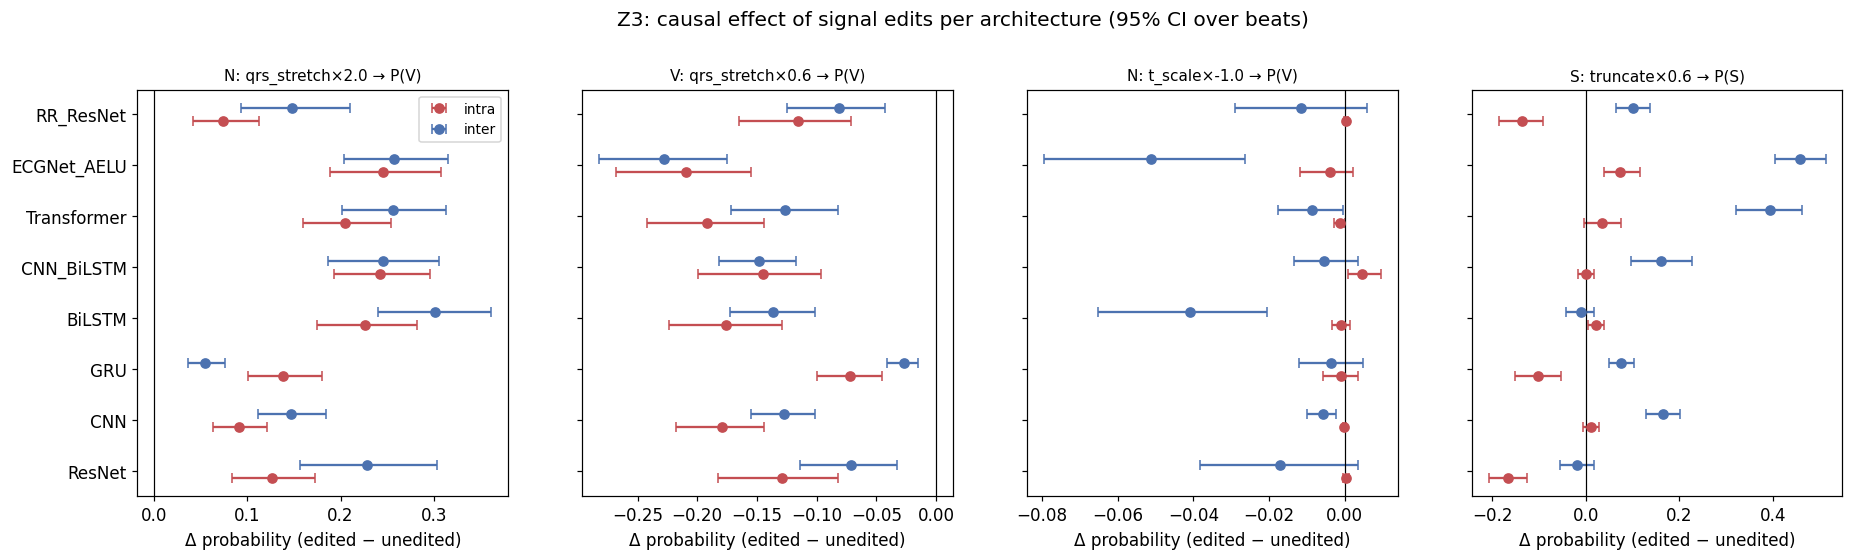

In [6]:
def landmarks(v):
    L = len(v); base = np.median(v); r = v[:3].max() - base; Tm = L / 1.2
    below = np.where(v < base + .5 * r)[0]; qhw = int(below[0]) if len(below) else L - 1
    qend = int(min(qhw + np.argmin(v[qhw:qhw + 15]) + 3, L - 2)) if qhw < L - 1 else L - 2
    lo = min(qend + 2, L - 2); hi = int(max(lo + 3, min(0.6 * Tm, L))); return dict(base=base, qend=qend, tlo=lo, thi=min(hi, L))
def edit(x, kind, s):
    x = x.copy(); L = int(valid_len(x)[0]); v = x[:L].astype(float); k = landmarks(v)
    if kind == "qrs_stretch":
        q = max(k["qend"], 3); n2 = max(2, int(round(q * s))); v2 = np.r_[np.interp(np.linspace(0, q - 1, n2), np.arange(q), v[:q]), v[q:]]
        v2 = v2[:L] if len(v2) >= L else np.r_[v2, np.full(L - len(v2), v[-1])]
    elif kind == "t_scale":
        w = np.zeros(L)
        if k["thi"] - k["tlo"] >= 3: w[k["tlo"]:k["thi"]] = np.hanning(k["thi"] - k["tlo"])
        v2 = v + (s - 1) * w * (v - k["base"])
    elif kind == "truncate":
        v2 = v.copy(); v2[int(round(s * L)):] = 0; x[:L] = v2; return x.astype(np.float32)
    x[:L] = np.clip(v2, 1e-4, 1); return x.astype(np.float32)
def p_edit(arch, arm, ix, kind, dose, tgt):
    Xe = _t = torch.as_tensor(np.stack([edit(X_all[i], kind, dose) for i in ix]), device=DEVICE); rr = GRR[arm][_ix(ix)]; out = []
    for s in SEEDS:
        m = MODELS[(arch, arm, s)]; m.eval()
        with torch.no_grad(): out.append(F.softmax(m(Xe, rr), 1)[:, tgt].cpu().numpy())
    return np.mean(out, 0)
EDITS = [("N", "qrs_stretch", 2.0, "V"), ("V", "qrs_stretch", .6, "V"), ("N", "t_scale", -1.0, "V"), ("S", "truncate", .6, "S")]
ED_ROWS = []
for arch in ARCHS:
    for cls, kind, dose, tgt in EDITS:
        ix = np.random.default_rng(7).permutation(POOL[y_all[POOL] == CLASSES.index(cls)])[:N_PER_CLASS]; ti = CLASSES.index(tgt); eff = {}
        for arm in ARMS:
            p0, p1 = p_edit(arch, arm, ix, kind, 1.0, ti), p_edit(arch, arm, ix, kind, dose, ti); eff[arm] = p1 - p0
            lo, hi = boot_ci(eff[arm]); ED_ROWS.append(dict(arch=arch, edit=f"{cls}: {kind}×{dose} → P({tgt})", arm=arm, p_unedited=float(p0.mean()), effect=float(eff[arm].mean()), ci_lo=lo, ci_hi=hi, n=len(ix)))
        lo, hi = boot_ci(eff["inter"] - eff["intra"]); ED_ROWS.append(dict(arch=arch, edit=f"{cls}: {kind}×{dose} → P({tgt})", arm="inter−intra", p_unedited=np.nan, effect=float((eff["inter"] - eff["intra"]).mean()), ci_lo=lo, ci_hi=hi, n=len(ix)))
ED = pd.DataFrame(ED_ROWS); ED.to_csv(OUT / "concept_edits_zoo.csv", index=False); print(ED.round(3).to_string(index=False))
RESULTS["concept_edits"] = ED.round(4).to_dict("records"); save_results()
fig, axes = plt.subplots(1, len(EDITS), figsize=(5 * len(EDITS), 4.8), sharey=True)
for ax, (cls, kind, dose, tgt) in zip(axes, EDITS):
    lab = f"{cls}: {kind}×{dose} → P({tgt})"
    for k, arm in enumerate(ARMS):
        d = ED[(ED.edit == lab) & (ED.arm == arm)].set_index("arch").reindex(ARCHS)
        ax.errorbar(d.effect, np.arange(len(ARCHS)) + (k - .5) * .25, xerr=[d.effect - d.ci_lo, d.ci_hi - d.effect], fmt="o", color=ACOL[arm], capsize=3, label=arm)
    ax.axvline(0, c="k", lw=.8); ax.set_title(lab, fontsize=10); ax.set_xlabel("Δ probability (edited − unedited)")
axes[0].set_yticks(range(len(ARCHS)), ARCHS); axes[0].legend(); fig.suptitle("Z3: causal effect of signal edits per architecture (95% CI over beats)", y=1.03); savefig(fig, "03_concept_edits_zoo")

## Z4 · Does explicit RR timing help on unseen patients?

In [7]:
if "RR_ResNet" in ARCHS and "ResNet" in ARCHS:
    z4 = {}
    for col in ["f1_4", "rec_S", "rec_V", "rec_F", "rec_N"]:
        a_ = PERF[(PERF.arch == "ResNet") & (PERF.arm == "inter")][col].values; b_ = PERF[(PERF.arch == "RR_ResNet") & (PERF.arm == "inter")][col].values
        z4[col] = dict(ResNet=f"{a_.mean():.3f}±{a_.std():.3f}", RR_ResNet=f"{b_.mean():.3f}±{b_.std():.3f}", gain=float(b_.mean() - a_.mean()), gain_in_seed_stds=float((b_.mean() - a_.mean()) / (max(a_.std(), b_.std()) + 1e-9)))
    print(json.dumps(z4, indent=1)); RESULTS["Z4_rr_vs_resnet_inter"] = z4; save_results()

{
 "f1_4": {
  "ResNet": "0.374\u00b10.015",
  "RR_ResNet": "0.441\u00b10.020",
  "gain": 0.06678752689455719,
  "gain_in_seed_stds": 3.375582986633221
 },
 "rec_S": {
  "ResNet": "0.102\u00b10.029",
  "RR_ResNet": "0.149\u00b10.021",
  "gain": 0.04728132387706856,
  "gain_in_seed_stds": 1.6366125039722466
 },
 "rec_V": {
  "ResNet": "0.862\u00b10.007",
  "RR_ResNet": "0.873\u00b10.007",
  "gain": 0.011211460604173107,
  "gain_in_seed_stds": 1.5131926619199216
 },
 "rec_F": {
  "ResNet": "0.031\u00b10.002",
  "RR_ResNet": "0.168\u00b10.085",
  "gain": 0.1374570446735395,
  "gain_in_seed_stds": 1.6177304058658692
 },
 "rec_N": {
  "ResNet": "0.786\u00b10.025",
  "RR_ResNet": "0.861\u00b10.018",
  "gain": 0.07481743547874986,
  "gain_in_seed_stds": 2.990327881348786
 }
}


## Summary (paste back for interpretation)

In [8]:
summ = {"performance_f1_4": PERF.groupby(["arch", "arm"]).f1_4.agg(lambda v: f"{v.mean():.3f}±{v.std():.3f}").unstack("arm").to_dict("index"),
        "inter_recall": PERF[PERF.arm == "inter"].groupby("arch")[["rec_N", "rec_S", "rec_V", "rec_F"]].mean().round(3).to_dict("index"),
        "explanation_shift": {f"{r.arch}|{r.method}": f"{r.shift:.3f} [{r.ci_lo:.3f},{r.ci_hi:.3f}]" for r in SHs.itertuples()},
        "shift_by_class_SmoothGrad": SHc[SHc.method == "SmoothGrad"].set_index("arch")[[c for c in CLASSES[:4] if c in SHc]].round(3).to_dict("index"),
        "concept_edits": {f"{r.arch}|{r.edit}|{r.arm}": f"{r.effect:.3f} [{r.ci_lo:.3f},{r.ci_hi:.3f}] p0={r.p_unedited:.2f}" for r in ED.itertuples()},
        "Z4": RESULTS.get("Z4_rr_vs_resnet_inter")}
print(json.dumps(summ, indent=1, default=str)); (OUT / "summary_for_review.json").write_text(json.dumps(summ, indent=1, default=str))
print("All outputs in:", OUT.resolve())

{
 "performance_f1_4": {
  "BiLSTM": {
   "inter": "0.399\u00b10.039",
   "intra": "0.679\u00b10.036"
  },
  "CNN": {
   "inter": "0.483\u00b10.022",
   "intra": "0.717\u00b10.027"
  },
  "CNN_BiLSTM": {
   "inter": "0.447\u00b10.042",
   "intra": "0.784\u00b10.066"
  },
  "ECGNet_AELU": {
   "inter": "0.348\u00b10.016",
   "intra": "0.654\u00b10.044"
  },
  "GRU": {
   "inter": "0.280\u00b10.089",
   "intra": "0.464\u00b10.199"
  },
  "RR_ResNet": {
   "inter": "0.441\u00b10.024",
   "intra": "0.827\u00b10.037"
  },
  "ResNet": {
   "inter": "0.374\u00b10.018",
   "intra": "0.818\u00b10.070"
  },
  "Transformer": {
   "inter": "0.453\u00b10.020",
   "intra": "0.731\u00b10.032"
  }
 },
 "inter_recall": {
  "BiLSTM": {
   "rec_N": 0.811,
   "rec_S": 0.136,
   "rec_V": 0.817,
   "rec_F": 0.046
  },
  "CNN": {
   "rec_N": 0.888,
   "rec_S": 0.159,
   "rec_V": 0.865,
   "rec_F": 0.317
  },
  "CNN_BiLSTM": {
   "rec_N": 0.829,
   "rec_S": 0.184,
   "rec_V": 0.859,
   "rec_F": 0.263
  },
  "

In [1]:
import shutil, os
src = "/content/outputs_zoo"
dst = "/content/drive/MyDrive/Research/outputs_zoo"
shutil.copytree(src, dst, dirs_exist_ok=True)
print("Copied:", sum(len(f) for _, _, f in os.walk(dst)), "files ->", dst)

Copied: 59 files -> /content/drive/MyDrive/Research/outputs_zoo


In [2]:
import time, subprocess, psutil
up = time.time() - psutil.boot_time()
print(f"Session running: {int(up//3600)}h {int(up%3600//60)}m")
print(f"RAM used: {psutil.virtual_memory().percent}%")
print(subprocess.run(["nvidia-smi", "--query-gpu=name,utilization.gpu,memory.used,memory.total",
                      "--format=csv,noheader"], capture_output=True, text=True).stdout)

Session running: 2h 40m
RAM used: 4.7%
NVIDIA A100-SXM4-40GB, 0 %, 6020 MiB, 40960 MiB

